# AML Investigation Prioritization — Guided Python Walkthrough

**Business question:** When an AML team can investigate only a fixed number of records, can a model put more relevant *synthetic benchmark labels* near the front of the queue?

This is a **step-by-step, beginner-friendly analysis** for people comfortable with pandas and basic statistics. It follows the same analytical story as the [live case study](https://mohammedmia1.github.io/AML_Data_Science_Project/).

### What you will learn

1. Inspect an account-day dataset and split it by time.
2. Turn raw feature columns into numeric model inputs.
3. Compare a simple logistic-regression baseline with XGBoost **on validation data**.
4. Translate model scores into a fixed review queue.
5. Confirm the held-out test results and understand a few **MLOps** practices.

**Important:** Every label is synthetic. A positive label does **not** establish actual crime, financial impact, or production performance. Only nine activity-based features enter the models.

## 1. Load the data and inspect its shape

**Why this matters:** Data analysts usually start by checking rows, columns, duplicates and dates. Machine learning starts the same way.

Each record represents **one account on one day**. We require the exact frozen TSV from `data/README.md`; the full file is not on GitHub because of its size.

The short setup below works in Jupyter launched from either the repository root or `notebooks/`. You can also set `AML_INPUT_DIR` to the folder containing the TSV.

In [1]:
from pathlib import Path
import hashlib
import os
import pandas as pd
import numpy as np
from IPython.display import display

# Find the project folder (works from the repository root or notebooks/).
project = Path.cwd()
if not (project / "reports" / "metrics.json").exists():
    project = project.parent

# Check that we are using the exact data from the published analysis.
data_folder = Path(os.environ.get("AML_INPUT_DIR", project / "data" / "local"))
data_file = data_folder / "aml_modeling_dev.tsv"
if not data_file.exists():
    raise FileNotFoundError(f"Missing dataset: {data_file}")

with open(data_file, "rb") as source:
    file_hash = hashlib.file_digest(source, "sha256").hexdigest()

expected_hash = "d6194ac2c29f4a90e4fa1e1740945ca2f558388a799020a15f16623eee9c6012"
assert file_hash == expected_hash, "The input differs from the published dataset."

transactions = pd.read_csv(data_file, sep="\t")
transactions["activity_date"] = pd.to_datetime(transactions["activity_date"])
print("Source checksum verified; data loaded.")


Source checksum verified; data loaded.


In [2]:
# Inspect the table before making features or fitting a model.
print("Rows:", len(transactions))
print("Columns:", len(transactions.columns))
print("Dates:", transactions["activity_date"].min().date(), "to",
      transactions["activity_date"].max().date())
print("Positive labels:", int(transactions["has_laundering_tx"].sum()))
print("Duplicate account-days:", transactions.duplicated(["account_id", "activity_date"]).sum())


Rows: 2479354
Columns: 13
Dates: 2022-09-01 to 2022-09-10
Positive labels: 7131
Duplicate account-days: 0


**Interpretation:** This is a large, imbalanced classification dataset. Most account-days have a zero label. A model that predicts zero for everything might have high accuracy, but it would not help investigators decide what to review.

## 2. Separate past activity from future activity

**Why this matters:** In a real analysis, we shouldn't train a model using future records and then pretend we are predicting the past. Instead of random shuffling, we divide records by date.

- **Training:** September 1–6, 2022 — learn model patterns.
- **Validation:** September 7–8 — compare methods and assess the review policy.
- **Test:** September 9–10 — assess the frozen choice on later, unseen records.

Using dates this way helps reduce **temporal leakage**. The dates and account IDs do not become model features.

In [3]:
train = transactions[transactions["activity_date"].between("2022-09-01", "2022-09-06")]
validation = transactions[transactions["activity_date"].between("2022-09-07", "2022-09-08")]
test = transactions[transactions["activity_date"].between("2022-09-09", "2022-09-10")]

split_summary = pd.DataFrame({
    "Rows": [len(train), len(validation), len(test)],
    "Positive labels": [int(train["has_laundering_tx"].sum()),
                        int(validation["has_laundering_tx"].sum()),
                        int(test["has_laundering_tx"].sum())]
}, index=["Training", "Validation", "Test"])

print(split_summary.to_string())
assert list(split_summary["Rows"]) == [1534403, 450244, 494707]

               Rows  Positive labels
Training    1534403             4003
Validation   450244             1629
Test         494707             1499


## 3. Build nine easy-to-explain features

A **feature** is simply a column used to make a prediction. Our nine features describe transaction volume, money movement, banking diversity and rapid activity.

Some amounts and counts are highly skewed. `np.log1p()` reduces their scale while keeping zeros valid. Three ratio/diversity columns are used without a log transform. We intentionally exclude `account_id`, the date and the target label.

This is plain pandas: create an empty DataFrame, loop through column names, and copy/transform columns.

In [4]:
log_columns = [
    "transaction_count", "total_sent", "total_received",
    "avg_transaction_amount", "max_transaction_amount", "unique_banks"
]
plain_columns = ["outgoing_ratio", "currency_diversity", "rapid_transaction_ratio"]

def make_features(rows):
    features = pd.DataFrame(index=rows.index)

    for column in log_columns:
        features["log_" + column] = np.log1p(rows[column])

    for column in plain_columns:
        features[column] = rows[column]

    assert np.isfinite(features.to_numpy()).all(), "Some features are missing or invalid."
    return features

X_train = make_features(train)
X_validation = make_features(validation)
X_test = make_features(test)

y_train = train["has_laundering_tx"]
y_validation = validation["has_laundering_tx"]
y_test = test["has_laundering_tx"]

print("Model feature count:", X_train.shape[1])
print("Features:", list(X_train.columns))

Model feature count: 9
Features: ['log_transaction_count', 'log_total_sent', 'log_total_received', 'log_avg_transaction_amount', 'log_max_transaction_amount', 'log_unique_banks', 'outgoing_ratio', 'currency_diversity', 'rapid_transaction_ratio']


## 4. Start with a simple baseline: logistic regression

**Why a baseline?** Before using a more complicated model, we should know what a familiar, simpler method can achieve.

Logistic regression combines feature values into a score. `StandardScaler` makes inputs comparable in scale; `class_weight="balanced"` adjusts for the low proportion of positive labels.

**PR-AUC (average precision)** summarizes how well a model puts rare positives near the top across thresholds. Higher is better. Here we measure it **on validation data**, not the held-out test.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

baseline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

baseline.fit(X_train, y_train)
baseline_scores = baseline.predict_proba(X_validation)[:, 1]

baseline_pr_auc = average_precision_score(y_validation, baseline_scores)
print("Logistic regression validation PR-AUC:", round(baseline_pr_auc, 4))

Logistic regression validation PR-AUC: 0.9999


## 5. Train XGBoost with a frozen configuration

**Why XGBoost?** Decision-tree models can learn interactions and nonlinear patterns that a linear model may miss. XGBoost combines many small trees into one ranking model.

The parameter values below are **the documented, frozen configuration** used for this case study. We do not change the model to chase test results. `n_jobs=2` and `random_state=42` help reproduce the same behavior in the pinned environment.

`scale_pos_weight` is calculated **only from training labels**, so validation and test labels don't leak into model fitting.

In [6]:
from xgboost import XGBClassifier

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
class_weight = negative_count / positive_count

model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=class_weight,
    random_state=42,
    n_jobs=2
)

model.fit(X_train, y_train)
xgb_scores = model.predict_proba(X_validation)[:, 1]

xgb_pr_auc = average_precision_score(y_validation, xgb_scores)
print("XGBoost validation PR-AUC:", round(xgb_pr_auc, 4))

XGBoost validation PR-AUC: 0.1286


## 6. Compare both methods under the same review workload

A higher PR-AUC is useful, but analysts also want a **decision-based metric**: how many positives would appear in the first **2,500 reviewed records**?

We sort each model's validation scores from highest to lowest and count positive labels in its first 2,500 rows. The same budget makes the comparison fair. The table below shows both statistical discrimination and potential queue quality.

**Important:** These are *validation-period measurements* newly reproduced from the frozen source. They are distinct from the previously published XGBoost **test-period** results.

In [7]:
review_budget = 2500
validation_labels = y_validation.to_numpy()

def count_positives_at_budget(scores, labels, budget):
    ranked_positions = np.argsort(-scores, kind="stable")
    top_labels = labels[ranked_positions[:budget]]
    return int(top_labels.sum())

baseline_found = count_positives_at_budget(baseline_scores, validation_labels, review_budget)
xgb_found = count_positives_at_budget(xgb_scores, validation_labels, review_budget)

comparison = pd.DataFrame({
    "Model": ["Logistic regression", "XGBoost"],
    "Validation PR-AUC": [baseline_pr_auc, xgb_pr_auc],
    "Validation ROC-AUC": [roc_auc_score(y_validation, baseline_scores),
                           roc_auc_score(y_validation, xgb_scores)],
    "Positives in first 2,500": [baseline_found, xgb_found],
    "Precision at 2,500": [baseline_found / review_budget, xgb_found / review_budget]
})

# Use Jupyter's HTML display instead of wrapping a plain-text table.
summary = comparison.copy()
summary["Validation PR-AUC"] = summary["Validation PR-AUC"].map("{:.4f}".format)
summary["Validation ROC-AUC"] = summary["Validation ROC-AUC"].map("{:.4f}".format)
summary["Positives in first 2,500"] = summary["Positives in first 2,500"].map("{:,}".format)
summary["Precision at 2,500"] = summary["Precision at 2,500"].map("{:.2%}".format)
display(summary)
assert baseline_found == 170 and xgb_found == 383

Model,Validation PR-AUC,Validation ROC-AUC,"Positives in first 2,500","Precision at 2,500"
Logistic regression,0.0378,0.7995,170,6.80%
XGBoost,0.1286,0.8446,383,15.32%


### What the models found at the same review budget

Each bar shows how many **positive synthetic labels** were ranked among the first **2,500 validation records**. Longer means more positives surfaced for the same amount of review work. This is a validation comparison, not an additional test result.


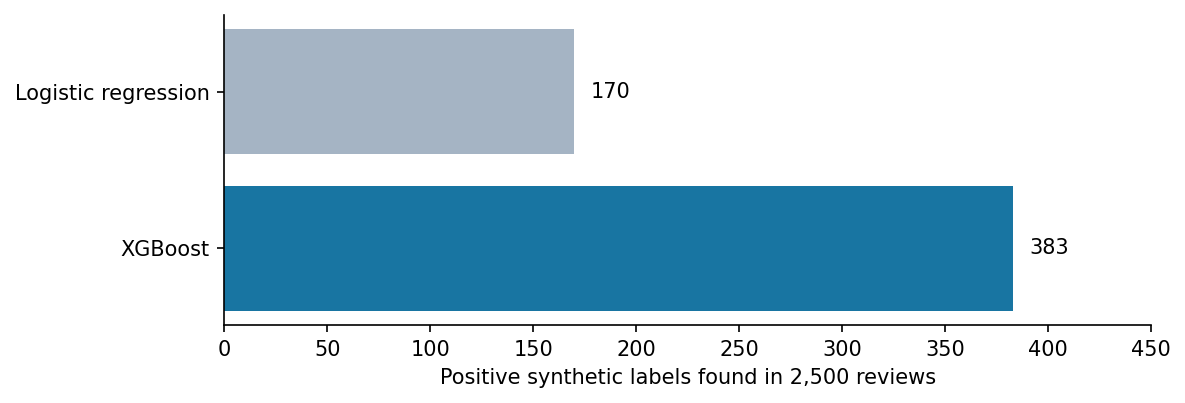

In [8]:
import matplotlib.pyplot as plt

# Both models received the same number of review slots.
model_names = ["Logistic regression", "XGBoost"]
positives_found = [baseline_found, xgb_found]

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(model_names, positives_found, color=["#A5B4C4", "#1875A2"])
ax.set_xlim(0, 450)
ax.set_xlabel("Positive synthetic labels found in 2,500 reviews")
ax.invert_yaxis()  # Display the simpler baseline first.
for bar, value in zip(bars, positives_found):
    ax.text(value + 8, bar.get_y() + bar.get_height() / 2, str(value), va="center")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


**What the comparison says:** XGBoost ranked **383** synthetic positives in the first 2,500 validation rows, versus **170** for logistic regression. Its validation PR-AUC was **0.1286** versus **0.0378**. This supports the use of XGBoost **for this frozen synthetic benchmark**, not a general claim that XGBoost will outperform other approaches in real AML systems.

The model choice is discussed transparently. These newly recorded validation figures should not be described as evidence of a previously run, exhaustive hyperparameter search.

## 7. Evaluate the frozen model on the later test period

Only now do we evaluate the held-out dates. The **2,500-row validation workload** is converted to the same fraction of the larger test dataset, yielding **2,747 review slots**.

We select the top-scored test rows and calculate:

- **Precision:** selected positives ÷ reviewed records.
- **Recall:** selected positives ÷ all positives in the test set.
- **Lift:** selected precision ÷ the positive-label rate in the full test set.

These metrics measure synthetic label ranking—not real investigations or prevented losses.

In [9]:
test_scores = model.predict_proba(X_test)[:, 1]
review_slots = round(len(test) * review_budget / len(validation))

test_labels = y_test.to_numpy()
selected_positives = count_positives_at_budget(test_scores, test_labels, review_slots)
precision = selected_positives / review_slots
recall = selected_positives / int(y_test.sum())
prevalence = float(y_test.mean())
lift = precision / prevalence

# Format each measure in the units that an investigator would expect.
results = pd.DataFrame({
    "Metric": ["Test account-days", "Review slots", "Positive labels selected",
               "Precision", "Recall", "Lift", "ROC-AUC", "PR-AUC"],
    "Value": [f"{len(test):,}", f"{review_slots:,}", f"{selected_positives:,}",
              f"{precision:.2%}", f"{recall:.2%}", f"{lift:.2f}×",
              f"{roc_auc_score(y_test, test_scores):.4f}",
              f"{average_precision_score(y_test, test_scores):.4f}"]
})
display(results)
assert (review_slots, selected_positives) == (2747, 389)

Metric,Value
Test account-days,"494,707"
Review slots,"2,747"
Positive labels selected,389
Precision,14.16%
Recall,25.95%
Lift,46.73×
ROC-AUC,0.8523
PR-AUC,0.1214


### Interpretation

At the fixed review rate, the model places **389 synthetic positive labels** among **2,747** reviewed account-days out of **494,707** held-out rows. That is **14.16% precision**, **25.95% recall**, and **46.73× lift** compared with random review of the same number of account-days.

![Published capacity curve and test-period outcome](../images/AML_Canonical_Dashboard.png)

The [interactive version](https://mohammedmia1.github.io/AML_Data_Science_Project/) lets you change the review budget. Its underlying 15,000-point curve is built from the frozen ranking, not fabricated chart data.

## 8. How we verified the project's reliability

A useful model needs more than a score. We also need to know **which data produced the results** and whether updates accidentally change the published analysis. These reliability practices are part of *MLOps* (Machine Learning Operations)—similar to checking that a recurring SQL report still uses the right data and calculations.

### Checks and recorded findings

| Question | Recorded finding | Evidence |
|:--|:--|:--|
| Did we load the expected source? | **Source checksum matched** during this notebook run. | Section 1; [input specification](../data/README.md) |
| Were account-day records duplicated? | **0 duplicated account-days** among **2,479,354** rows. | Section 1 output |
| Were train, validation and test separated by date? | **1,534,403 / 450,244 / 494,707** rows in chronological partitions. | Section 2 output |
| Do saved notebook results match the published benchmark? | The committed [notebook-evidence test](../tests/check_notebook_evidence.py) checks the recorded validation comparison and held-out values against [published metrics](../reports/metrics.json). | [Test script](../tests/check_notebook_evidence.py) |
| Will future GitHub changes trigger checks? | A [GitHub Actions workflow](../.github/workflows/validate.yml) is configured to check committed results and notebook evidence on pushes. **This notebook alone cannot confirm the latest cloud run passed.** | [Workflow](../.github/workflows/validate.yml) · [Run history](https://github.com/mohammedmia1/AML_Data_Science_Project/actions) |

**How to read this:** A check that passes means the *specific condition tested* was satisfied. It does not prove the model is suitable for a real bank. These checks help detect wrong inputs, duplicated account-day records and inconsistent published results.

**What is not tested here:** live transactions, production monitoring, automated retraining, real-world crime detection, or the complete raw-SQL-to-frozen-TSV reconstruction. The full model is not retrained by GitHub Actions because the large source dataset is not stored in this repository.


## 9. Reproducing the published files

For a *full rerun*, use the [canonical training script](../src/run_canonical.py). It writes the model, full scored export, metrics JSON and website capacity JSON to `artifacts/`.

For a *quick verification* without the large TSV, run `python tests/check_artifacts.py` from the repository root. This checks the published metrics and chart-data contract, but does not refit XGBoost.

The original analytical outputs were recorded from the checksum-verified synthetic TSV. The comparison table and test summary were reformatted from those recorded values; the bar chart was drawn from the same verified validation counts. **This presentation update was not a new full notebook training run.** It also does not establish that the SQL raw-data extraction was freshly repeated.

## 10. Limitations and suggested next experiments

- These are **synthetic benchmark labels**, not confirmed money laundering.
- The held-out test covers only **two days**; additional temporal holdouts are needed to assess stability.
- The account-day granularity means one account can appear on different days.
- Scores rank records but have not been proven to be calibrated probabilities.
- The SQL source-to-TSV reconstruction has been reviewed but has **not** been independently reconciled against raw transactions.
- No investigator time, alert disposition, cost savings, live deployment or model monitoring were measured.

**Next responsible steps:** Compare additional temporal holdouts, independently verify the SQL export against the frozen TSV, and evaluate workload/cost trade-offs using actual operational definitions if suitable data becomes available.

[Back to project README](../README.md) · [Technical guide](../PROJECT_GUIDE.md) · [Live case study](https://mohammedmia1.github.io/AML_Data_Science_Project/)